# Лабораторная работа №2
Выполнили Шакина Анна, Воробьев Андрей
## Задание 1. Функции влияния и асимптотическая дисперсия

### 1. Выберем модель и оценки

Мы решили выбрать модель оценивания параметра сдвига:
$$X_i=\mu+\sigma Z_i,\qquad Z_i\overset{\mathrm{iid}}\sim N(0,1),\quad \mu\in\mathbb R.$$
Масштаб $\sigma=2$ зафиксируемм; положим $\mu=5$. Обозначим через $\varphi$ и $\Phi$ плотность и функцию распределения $N(0,1)$.

Рассмотрим среднее $\bar X$, медиану $\hat\mu_{\mathrm{med}}$ и две M-оценки Губера с $c=1$ и $c=1.345$.

In [25]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.polynomial.legendre import leggauss
from scipy.integrate import quad
from scipy.optimize import brentq, minimize_scalar
from scipy.stats import cauchy, norm

MU, SIGMA = 5.0, 2.0
C_VALUES = (1.0, 1.345)
NAMES = ["Среднее", "Медиана", "Губер, c=1", "Губер, c=1.345"]
rng_sample = np.random.default_rng(27102026)
rng_if = np.random.default_rng(27102027)
rng_sim = np.random.default_rng(27102028)
pd.set_option("display.precision", 5)
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.25})
print(f"Распределение: N(mu, {SIGMA**2:g}), истинный сдвиг mu = {MU:g}")
print(f"Python {sys.version.split()[0]}; NumPy {np.__version__}")

Распределение: N(mu, 4), истинный сдвиг mu = 5
Python 3.13.3; NumPy 2.2.4


Мы выбрали нормальное распределение с известным масштабом. Все оценки оценивают один параметр $\mu$.

Для M-оценок выберем ограниченную функцию
$$\psi_c(u)=\begin{cases}-c,&u<-c,\\u,&|u|\le c,\\c,&u>c.\end{cases}$$
Ей соответствует выпуклая функция потерь
$$\rho_c(u)=\begin{cases}u^2/2,&|u|\le c,\\c|u|-c^2/2,&|u|>c.\end{cases}$$
Вычислим $\hat\mu_c$ из $\sum_{i=1}^n\psi_c((X_i-\hat\mu_c)/\sigma)=0$. По симметрии $\mathbb E\psi_c(Z)=0$, поэтому для выбранного распределения предельное значение каждой M-оценки равно $\mu$. Корень найдём методом Ньютона с ограничением шага интервалом поиска; при выходе из интервала используем бисекцию.

In [26]:
def psi_huber(u, c):
    return np.clip(u, -c, c)

def huber_batch(samples, c, sigma=SIGMA, tol=1e-11, max_iter=80):
    """Одна оценка на строку; масштаб известен."""
    x = np.atleast_2d(np.asarray(samples, dtype=float))
    left, right = x.min(axis=1), x.max(axis=1)
    t = np.median(x, axis=1)
    for _ in range(max_iter):
        u = (x - t[:, None]) / sigma
        score = psi_huber(u, c).mean(axis=1)
        if np.max(np.abs(score)) < tol:
            return t
        left = np.where(score > 0, t, left)
        right = np.where(score < 0, t, right)
        slope = (np.abs(u) < c).mean(axis=1)
        step = sigma * score / np.maximum(slope, 1e-15)
        proposal = t + step
        inside = (proposal > left) & (proposal < right)
        proposal = np.where(inside, proposal, (left + right) / 2)
        t = np.where(np.abs(score) < tol, t, proposal)
    raise RuntimeError("Не достигнута заданная точность M-оценки")

def estimate_batch(samples):
    x = np.atleast_2d(samples)
    return np.column_stack([x.mean(axis=1), np.median(x, axis=1),
                            *(huber_batch(x, c) for c in C_VALUES)])

x_demo = rng_sample.normal(MU, SIGMA, size=201)
demo = pd.DataFrame({'Оценка mu': estimate_batch(x_demo)[0]}, index=NAMES)
demo['Отклонение от mu'] = demo['Оценка mu'] - MU
display(demo)

# Проверим совпадение решений, найденных двумя методами.
for c in C_VALUES:
    root = brentq(lambda t: psi_huber((x_demo - t) / SIGMA, c).sum(),
                  x_demo.min(), x_demo.max(), xtol=1e-12)
    np.testing.assert_allclose(huber_batch(x_demo, c)[0], root, atol=1e-9, rtol=0)
print("M-оценки совпали с brentq с точностью 1e-9.")

,Оценка mu,Отклонение от mu
Среднее,5.00963,0.00963
Медиана,4.92920,-0.07080
"Губер, c=1",4.98572,-0.01428
"Губер, c=1.345",4.99715,-0.00285


M-оценки совпали с brentq с точностью 1e-9.


Мы получили четыре оценки на одной выборке. Их различия отражают случайный разброс; по одной реализации нельзя сравнить дисперсии. Результаты двух методов поиска корня совпали с заданной точностью.

### 2. Вычислим функции влияния

Обозначим через $T(F)$ предельное значение оценки при распределении $F$. Для распределения с выбросами $F_\epsilon=(1-\epsilon)F+\epsilon\Delta_x$, где $\Delta_x$ - вырожденное распределение в точке $x$, определим
$$\operatorname{IF}(x;T,F)=\left.\frac{d}{d\epsilon}T(F_\epsilon)\right|_{\epsilon=0+}.$$
Она описывает изменение оценки при малой доле выбросов: $T(F_\epsilon)-T(F)=\epsilon\operatorname{IF}(x;T,F)+o(\epsilon)$ при фиксированном $x$.

**Среднее.** Поскольку $T(F_\epsilon)=(1-\epsilon)\mu+\epsilon x$,
$$\boxed{\operatorname{IF}_{\mathrm{mean}}(x,F)=x-\mu.}$$

**Медиана.** Для $x\ne\mu$ дифференцируем уравнение $F_\epsilon(m_\epsilon)=1/2$:
$$-\frac12+f(\mu)m'_0+\mathbf1_{\{x\le\mu\}}=0.$$
Следовательно,
$$\boxed{\operatorname{IF}_{\mathrm{med}}(x,F)=\frac{\operatorname{sign}(x-\mu)}{2f(\mu)}
=\sigma\sqrt{\frac\pi2}\operatorname{sign}(x-\mu).}$$
В точке $x=\mu$ медиана распределения с выбросами остаётся равной $\mu$, поэтому положим $\operatorname{IF}_{\mathrm{med}}(\mu,F)=0$.

**M-оценки Губера.** Предельное значение каждой оценки задаётся уравнением
$\mathbb E_{F_\epsilon}\psi_c((X-T_c(F_\epsilon))/\sigma)=0$. При дифференцировании получим
$$-\underbrace{\mathbb E_F\psi_c(Z)}_{0}
-\frac{T'_c(0)}{\sigma}\mathbb E\psi'_c(Z)
+\psi_c\!\left(\frac{x-\mu}{\sigma}\right)=0.$$
Так как $\psi'_c(z)=\mathbf1_{\{|z|<c\}}$ почти всюду,
$$A_c=\mathbb E\psi'_c(Z)=2\Phi(c)-1,\qquad
\boxed{\operatorname{IF}_c(x,F)=\frac{\sigma\psi_c((x-\mu)/\sigma)}{A_c}.}$$
Точки излома $\pm c$ имеют нулевую вероятность. Подставим оба порога и построим все функции влияния.

    c     A_c  sigma/A_c
1.000 0.68269    2.92959
1.345 0.82137    2.43494


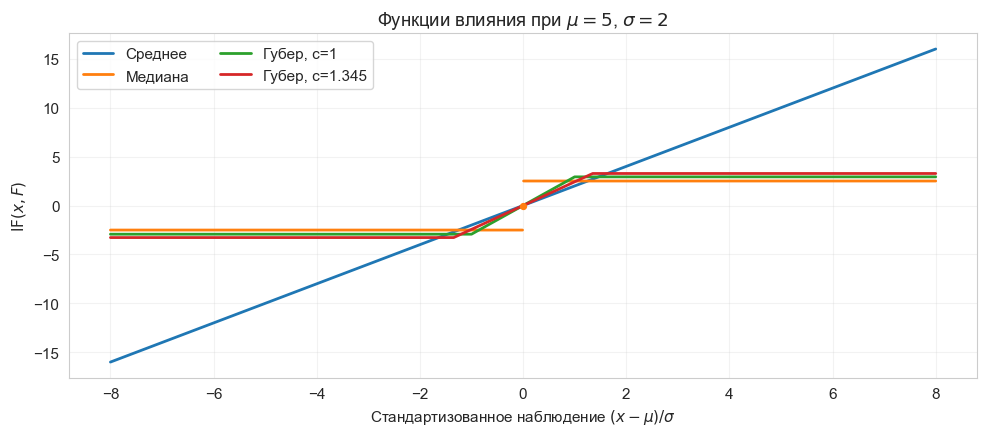

In [27]:
def A(c):
    return 2 * norm.cdf(c) - 1

def influence(x):
    z = (np.asarray(x) - MU) / SIGMA
    return np.stack([SIGMA * z, SIGMA * np.sqrt(np.pi / 2) * np.sign(z),
                     *(SIGMA * psi_huber(z, c) / A(c) for c in C_VALUES)], axis=-1)

print(pd.DataFrame({"c": C_VALUES, "A_c": [A(c) for c in C_VALUES],
                    'sigma/A_c': [SIGMA / A(c) for c in C_VALUES]}).to_string(index=False))
z_grid = np.linspace(-8, 8, 1601)
if_grid = influence(MU + SIGMA * z_grid)
fig, ax = plt.subplots(figsize=(10, 4.5))
for j, name in enumerate(NAMES):
    y = if_grid[:, j].copy()
    if j == 1:
        y[np.isclose(z_grid, 0)] = np.nan  # Не соединяем скачок медианы.
    ax.plot(z_grid, y, label=name, linewidth=2)
ax.scatter([0], [0], s=18, color="tab:orange", zorder=5)
ax.set(xlabel='Стандартизованное наблюдение $(x-\\mu)/\\sigma$',
       ylabel='$\\mathrm{IF}(x,F)$', title='Функции влияния при $\\mu=5$, $\\sigma=2$')
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

### 3. Найдём чувствительность к грубым ошибкам

Чувствительность к грубым ошибкам равна $\gamma^*(T,F)=\sup_{x\in\mathbb R}|\operatorname{IF}(x;T,F)|$. Поэтому
$$\gamma^*_{\mathrm{mean}}=\infty,\qquad
\gamma^*_{\mathrm{med}}=\sigma\sqrt{\pi/2},\qquad
\gamma^*_c=\frac{\sigma c}{2\Phi(c)-1}.$$
Вычислим значения по полученным формулам. Для среднего функция влияния не ограничена, поэтому сразу укажем $\infty$.

In [28]:
gamma = np.array([np.inf, SIGMA * np.sqrt(np.pi / 2),
                  *(SIGMA * c / A(c) for c in C_VALUES)])
sensitivity = pd.DataFrame({'gamma^*': gamma, "Ограниченная IF": np.isfinite(gamma)},
                           index=NAMES)
display(sensitivity)

,gamma^*,Ограниченная IF
Среднее,inf,False
Медиана,2.50663,True
"Губер, c=1",2.92959,True
"Губер, c=1.345",3.27500,True


Мы получили $\gamma^*=\infty$ для среднего, $2.50663$ для медианы, $2.92959$ и $3.27500$ для оценок Губера с $c=1$ и $c=1.345$. Среди рассмотренных оценок медиана имеет наименьшую чувствительность к грубым ошибкам. При увеличении порога Губера эта чувствительность возрастает.

### 4. Найдём теоретическую асимптотическую дисперсию

Под $v^2$ понимаем дисперсию предельного закона:
$$\sqrt n(\hat\mu-\mu)\Rightarrow N(0,v^2),\qquad
\operatorname{Var}(\hat\mu)\approx v^2/n.$$
Для среднего $v^2_{\mathrm{mean}}=\sigma^2$, а из асимптотики выборочной медианы
$$v^2_{\mathrm{med}}=\frac{1}{4f(\mu)^2}=\frac{\pi\sigma^2}{2}.$$
Разложение уравнения M-оценки по формуле Тейлора даёт
$$\sqrt n(\hat\mu_c-\mu)=\frac{\sigma}{A_c\sqrt n}\sum_{i=1}^n\psi_c(Z_i)+o_P(1),\qquad
v_c^2=\frac{\sigma^2 B_c}{A_c^2}.$$
Вычислим числитель интегрированием по частям:
$$B_c=\mathbb E\psi_c(Z)^2
=\int_{-c}^c z^2\varphi(z)\,dz+2c^2[1-\Phi(c)]
=A_c-2c\varphi(c)+2c^2[1-\Phi(c)].$$
Независимо проинтегрируем квадраты найденных IF и сравним с этими формулами.

In [29]:
def B(c):
    return A(c) - 2 * c * norm.pdf(c) + 2 * c**2 * norm.sf(c)

v2 = np.array([SIGMA**2, np.pi * SIGMA**2 / 2,
               *(SIGMA**2 * B(c) / A(c)**2 for c in C_VALUES)])
integrals = []
for j in range(len(NAMES)):
    # Разбиваем интеграл в точках излома и скачка
    cuts = [-np.inf, -C_VALUES[1], -C_VALUES[0], 0,
            C_VALUES[0], C_VALUES[1], np.inf]
    value = sum(quad(lambda z: influence(MU + SIGMA * z)[j]**2 * norm.pdf(z),
                     lo, hi, epsabs=1e-10)[0] for lo, hi in zip(cuts[:-1], cuts[1:]))
    integrals.append(value)
theory = pd.DataFrame({'v^2 по формуле': v2, 'Интеграл IF^2': integrals,
                       'Эффективность sigma^2/v^2': SIGMA**2 / v2}, index=NAMES)
display(theory)
np.testing.assert_allclose(integrals, v2, rtol=1e-9, atol=1e-9)

,v^2 по формуле,Интеграл IF^2,Эффективность sigma^2/v^2
Среднее,4.00000,4.00000,1.00000
Медиана,6.28319,6.28319,0.63662
"Губер, c=1",4.42907,4.42907,0.90312
"Губер, c=1.345",4.21053,4.21053,0.95000


Интегралы квадратов IF совпали с формулами: $v^2=4$ для среднего, $6.28319$ для медианы, $4.42907$ и $4.21053$ для оценок Губера. Для нормального распределения M-оценка с $c=1.345$ сохраняет около $95\%$ эффективности среднего, с $c=1$ - около $90.3\%$, медиана - около $63.7\%$. Ограничение влияния сопровождается увеличением дисперсии.

### 5. Оценим $\mathbb E_F[\operatorname{IF}(X,F)^2]$ по случайной выборке

Сгенерируем независимо $M=500\,000$ наблюдений из $F=N(5,4)$. По закону больших чисел
$$\widehat q_M=\frac1M\sum_{i=1}^M\operatorname{IF}(X_i,F)^2
\xrightarrow{P}\mathbb E_F[\operatorname{IF}(X,F)^2].$$
Стандартную ошибку Монте-Карло оценим как $s(\operatorname{IF}^2)/\sqrt M$. Интервал $\widehat q_M\pm1.96\,\operatorname{SE}$ описывает случайную погрешность этого среднего.

In [30]:
M = 500_000
x_if = rng_if.normal(MU, SIGMA, size=M)
if_squared = influence(x_if)**2
q_mc = np.array([column.mean() for column in if_squared.T])
q_se = np.array([column.std(ddof=1) for column in if_squared.T]) / np.sqrt(M)
if_mc = pd.DataFrame({'v^2': v2, 'Среднее IF^2': q_mc, 'SE среднего IF^2': q_se,
                      "Нижняя граница 95%": q_mc - 1.96 * q_se,
                      "Верхняя граница 95%": q_mc + 1.96 * q_se,
                      "Относительная ошибка, %": 100 * (q_mc / v2 - 1)}, index=NAMES)
display(if_mc)

,v^2,Среднее IF^2,SE среднего IF^2,Нижняя граница 95%,Верхняя граница 95%,"Относительная ошибка, %"
Среднее,4.00000,3.99083,7.99762e-03,3.97516,4.00651,-2.29191e-01
Медиана,6.28319,6.28319,8.79253e-18,6.28319,6.28319,-1.11022e-13
"Губер, c=1",4.42907,4.42399,4.90524e-03,4.41438,4.43361,-1.14656e-01
"Губер, c=1.345",4.21053,4.20399,5.65627e-03,4.19291,4.21508,-1.55103e-01


Средние квадратов IF составили примерно $3.99083$, $6.28319$, $4.42399$ и $4.20399$; относительные ошибки не превышают $0.23\%$. Для среднего и M-оценок расхождения укладываются в приведённые интервалы, полученные при моделировании. У медианы $\operatorname{IF}^2=\pi\sigma^2/2$ почти наверное, поэтому случайная погрешность этого среднего равна нулю; возможны лишь ошибки округления.

### 6. Оценим дисперсию самих оценок

Для каждого $n\in\{51,201,1001,3001\}$ сгенерируем $R=10\,000$ независимых выборок. На каждой вычислим все четыре оценки и положим
$$Y_r=\sqrt n(\hat\mu^{(r)}-\mu),\qquad
\widehat v_n^2=\frac1{R-1}\sum_{r=1}^R(Y_r-\bar Y)^2.$$
Это независимая проверка: здесь используем разброс оценок, а не их IF. Для случайной ошибки $\widehat v_n^2$ применим приближение
$$\widehat{\operatorname{SE}}(\widehat v_n^2)=
\sqrt{\frac{\max(0,\hat m_4-(\widehat v_n^2)^2)}{R}},\qquad
\hat m_4=\frac1R\sum_{r=1}^R(Y_r-\bar Y)^4.$$
Интервалы $\widehat v_n^2\pm1.96\widehat{\operatorname{SE}}$ приближённые. Каждый интервал построен отдельно для одной оценки при одном значении $n$. Они относятся к $n\operatorname{Var}(\hat\mu)$ при данном объёме выборки; эта величина стремится к $v^2$ при увеличении $n$.

In [31]:
R = 10_000
SAMPLE_SIZES = (51, 201, 1001, 3001)
BATCH_SIZE = 250
records = []
for n in SAMPLE_SIZES:
    estimates = np.empty((R, len(NAMES)))
    for start in range(0, R, BATCH_SIZE):
        stop = min(start + BATCH_SIZE, R)
        samples = rng_sim.normal(MU, SIGMA, size=(stop - start, n))
        estimates[start:stop] = estimate_batch(samples)
    y = np.sqrt(n) * (estimates - MU)
    centered = y - y.mean(axis=0)
    empirical_v2 = y.var(axis=0, ddof=1)
    m4 = np.mean(centered**4, axis=0)
    variance_se = np.sqrt(np.maximum(0, m4 - empirical_v2**2) / R)
    for j, name in enumerate(NAMES):
        records.append({"n": n, "Оценка": name,
                        "Смещение": estimates[:, j].mean() - MU,
                        'n*Var(mu_hat)': empirical_v2[j], 'v^2': v2[j],
                        'Среднее IF^2': q_mc[j], "SE дисперсии": variance_se[j],
                        "Нижняя граница 95%": empirical_v2[j] - 1.96 * variance_se[j],
                        "Верхняя граница 95%": empirical_v2[j] + 1.96 * variance_se[j],
                        "Относительная ошибка, %": 100 * (empirical_v2[j] / v2[j] - 1)})
simulation = pd.DataFrame(records)
display(simulation.set_index(["n", "Оценка"]))

Смещение  n*Var(mu_hat)      v^2  Среднее IF^2  \
n    Оценка                                                           
51   Среднее         -0.00136        3.85274  4.00000       3.99083   
     Медиана         -0.00035        6.10992  6.28319       6.28319   
     Губер, c=1      -0.00073        4.28433  4.42907       4.42399   
     Губер, c=1.345  -0.00065        4.05731  4.21053       4.20399   
201  Среднее          0.00043        4.15018  4.00000       3.99083   
     Медиана         -0.00027        6.38084  6.28319       6.28319   
     Губер, c=1       0.00026        4.58206  4.42907       4.42399   
     Губер, c=1.345   0.00053        4.36684  4.21053       4.20399   
1001 Среднее         -0.00024        3.98650  4.00000       3.99083   
     Медиана         -0.00070        6.24296  6.28319       6.28319   
     Губер, c=1      -0.00027        4.36820  4.42907       4.42399   
     Губер, c=1.345  -0.00026        4.16552  4.21053       4.20399   
3001 Среднее          0.00060        4.03891  4.00000       3.99083   
     Медиана          0.00107        6.29893  6.28319       6.28319   
     Губер, c=1       0.00091        4.47867  4.42907       4.42399   
     Губер, c=1.345   0.00073        4.24348  4.21053       4.20399   

                     SE дисперсии  Нижняя граница 95%  Верхняя граница 95%  \
n    Оценка                                                                  
51   Среднее              0.05380             3.74728              3.95819   
     Медиана              0.08637             5.94063              6.27922   
     Губер, c=1           0.06048             4.16579              4.40288   
     Губер, c=1.345       0.05677             3.94605              4.16857   
201  Среднее              0.05881             4.03491              4.26545   
     Медиана              0.09090             6.20267              6.55901   
     Губер, c=1           0.06496             4.45474              4.70939   
     Губер, c=1.345       0.06199             4.24534              4.48835   
1001 Среднее              0.05614             3.87647              4.09653   
     Медиана              0.08673             6.07297              6.41295   
     Губер, c=1           0.06083             4.24897              4.48742   
     Губер, c=1.345       0.05831             4.05122              4.27981   
3001 Среднее              0.05748             3.92625              4.15157   
     Медиана              0.09071             6.12114              6.47673   
     Губер, c=1           0.06433             4.35259              4.60475   
     Губер, c=1.345       0.06073             4.12445              4.36250   

                     Относительная ошибка, %  
n    Оценка                                   
51   Среднее                        -3.68157  
     Медиана                        -2.75754  
     Губер, c=1                     -3.26784  
     Губер, c=1.345                 -3.63885  
201  Среднее                         3.75447  
     Медиана                         1.55428  
     Губер, c=1                      3.45433  
     Губер, c=1.345                  3.71257  
1001 Среднее                        -0.33756  
     Медиана                        -0.64019  
     Губер, c=1                     -1.37441  
     Губер, c=1.345                 -1.06891  
3001 Среднее                         0.97271  
     Медиана                         0.25064  
     Губер, c=1                      1.11995  
     Губер, c=1.345                  0.78258

При $n=3001$ мы получили $n\widehat{\operatorname{Var}}(\hat\mu)$, равные $4.03891$, $6.29893$, $4.47867$ и $4.24348$: отклонения от предельных значений не превышают $1.12\%$, и все четыре значения $v^2$ попали в соответствующие интервалы.

При $n=51$ и $201$ часть интервалов не содержит предела. Каждый интервал построен отдельно, поэтому все интервалы не обязаны одновременно содержать соответствующие теоретические значения; для среднего $n\operatorname{Var}(\bar X)=\sigma^2$ точно при любом $n$, поэтому его отклонения вызваны погрешностью Монте-Карло. Для медианы и M-оценок дисперсия при данном объёме выборки также может отличаться от предельного значения.

Сопоставим $n\widehat{\operatorname{Var}}(\hat\mu)$, теоретическое $v^2$ и независимое среднее $\operatorname{IF}^2$. Вертикальные отрезки покажут погрешность моделирования. Сходимость дисперсий не обязана быть монотонной из-за конечного числа повторений.

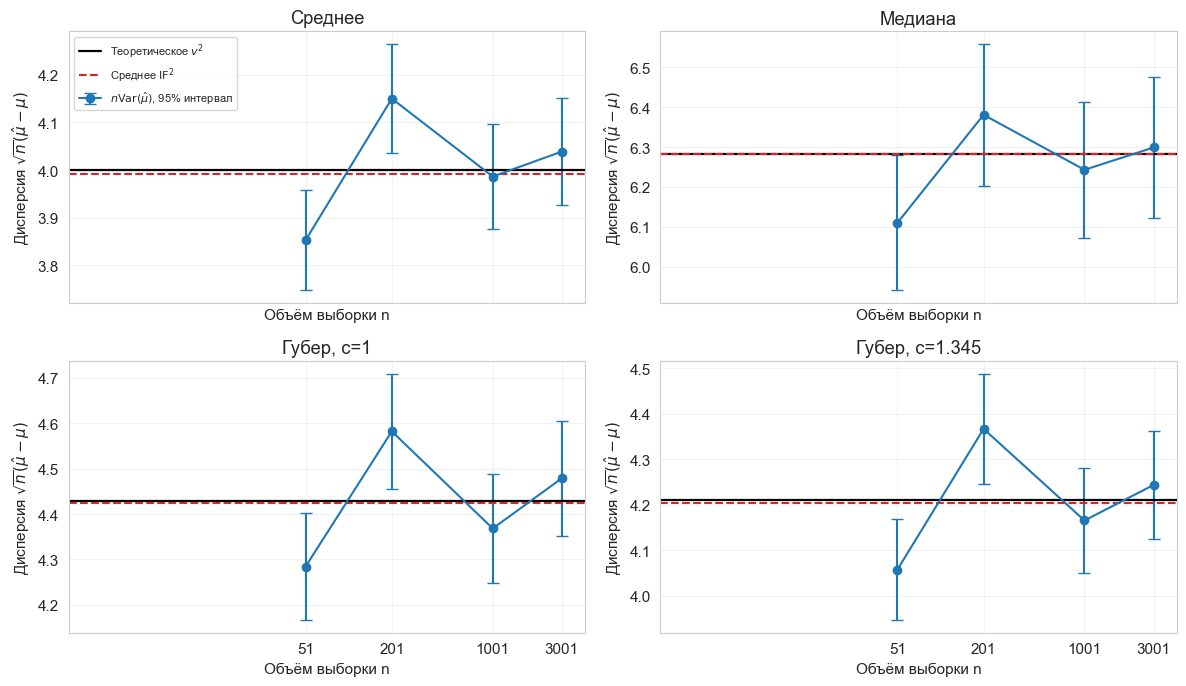

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for j, (name, ax) in enumerate(zip(NAMES, axes.flat)):
    part = simulation[simulation["Оценка"] == name]
    ax.errorbar(part["n"], part['n*Var(mu_hat)'],
                yerr=1.96 * part["SE дисперсии"], fmt="o-", capsize=4,
                label='$n\\mathrm{Var}(\\hat{\\mu})$, 95% интервал')
    ax.axhline(v2[j], color="black", linewidth=1.6, label='Теоретическое $v^2$')
    ax.axhline(q_mc[j], color="tab:red", linestyle="--", label='Среднее $\\mathrm{IF}^2$')
    ax.set(xscale="log", title=name, xlabel="Объём выборки n", ylabel='Дисперсия $\\sqrt{n}(\\hat{\\mu}-\\mu)$')
    ax.set_xticks(SAMPLE_SIZES, [str(n) for n in SAMPLE_SIZES])
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

На графиках дисперсии оценок, умноженные на $n$, колеблются около теоретических уровней и независимых средних квадратов IF. При больших $n$ результаты согласуются с равенством $v^2=\mathbb E_F[\operatorname{IF}(X,F)^2]$ в пределах точности моделирования. Уменьшение погрешности Монте-Карло требует увеличения числа повторений $R$, а не только объёма выборки $n$.

### Вывод

Мы нашли функции влияния всех четырёх оценок и их чувствительность к грубым ошибкам (gross-error sensitivity). Среднее имеет неограниченную IF, а медиана и обе M-оценки Губера ограничивают влияние выбросов при малой доле выбросов.

Моделирование согласуется с равенством $v^2=\mathbb E_F[\operatorname{IF}(X,F)^2]$: среднее квадрата IF и масштабированная дисперсия оценок близки к одному теоретическому значению. Это численная проверка для выбранного распределения, а не доказательство общего утверждения.

При точном соответствии нормальному распределению наименьшую асимптотическую дисперсию даёт среднее. Если требуется ограничить влияние отдельных выбросов и сохранить высокую эффективность, мы выбираем M-оценку Губера с $c=1.345$. Порог $c=1$ сильнее ограничивает влияние ценой большей дисперсии; медиана даёт наименьшую чувствительность среди рассмотренных оценок.

## Задание 2. Breakdown point и информативность оценки

Мы решили выбрать выборочную медиану: её предельный breakdown point равен $1/2$. Исследуем, остаётся ли оценка ограниченной при увеличении величины выбросов, и отдельно оценим её точность.

### 1. Зададим схему эксперимента

Обычные наблюдения имеют распределение $N(\mu,\sigma^2)$, где $\mu = 5$, $\sigma = 2$. К $n=200$ обычным наблюдениям добавим $m$ одинаковых выбросов
$$a_L=\mu+L\,\sigma,\qquad
\epsilon=\frac{m}{n+m}.$$
Долю выбросов считаем от итогового объёма выборки. Выберем $L=10,30,100,300,1000$ и доли ниже, около и выше $1/2$. Для каждой ситуации выполним 4000 повторений. Во всех ситуациях используем одни и те же обычные выборки, чтобы сравнить влияние добавленных выбросов.

In [33]:
MU_BP, SIGMA_BP = 5.0, 2.0
N_CLEAN_BP, REPEATS_BP = 200, 4000
M_VALUES_BP = np.array([0, 20, 50, 100, 150, 180, 190, 198, 199,
                        200, 201, 202, 210, 250, 300])
L_VALUES_BP = np.array([10.0, 30.0, 100.0, 300.0, 1000.0])
rng_bp = np.random.default_rng(27102029)
clean_bp = rng_bp.normal(MU_BP, SIGMA_BP, size=(REPEATS_BP, N_CLEAN_BP))
pd.set_option("display.precision", 5)
print(f"Обычные данные: N(mu, sigma^2), mu = {MU_BP:g}, sigma = {SIGMA_BP:g}")
print(f"Число обычных наблюдений: {N_CLEAN_BP}; повторений: {REPEATS_BP}")
print(f"Диапазон epsilon: от 0 до {M_VALUES_BP[-1] / (N_CLEAN_BP + M_VALUES_BP[-1]):.2f}")
print("Значения L:", L_VALUES_BP)

Обычные данные: N(mu, sigma^2), mu = 5, sigma = 2
Число обычных наблюдений: 200; повторений: 4000
Диапазон epsilon: от 0 до 0.60
Значения L: [  10.   30.  100.  300. 1000.]


Мы зафиксировали число обычных наблюдений и будем изменять число и величину добавленных выбросов. Максимальная доля выбросов равна 0.6, поэтому эксперимент охватывает обе стороны порога 1/2.

### 2. Рассмотрим поведение на границе

Если $m<n$, обычные наблюдения составляют большинство. При любых значениях выбросов медиана остаётся между минимумом и максимумом обычной выборки. Это означает ограниченность при фиксированной исходной выборке, но не гарантирует малую ошибку.

Пусть $a_L$ больше всех обычных наблюдений, а $x_{\max}$ - их максимум. При обычном определении медианы чётной выборки как среднего двух центральных значений получим
$$\widehat{\mu}_{\mathrm{med}}=
\begin{cases}
x_{\max},&m=n-1,\\
(x_{\max}+a_L)/2,&m=n,\\
a_L,&m=n+1.
\end{cases}$$
Поэтому 199 добавлений ещё сохраняют ограниченность, а 200 уже позволяют увести оценку неограниченно далеко. В определении через максимальную допустимую долю добавлений получаем $199/399\approx0.49875$; при увеличении $n$ эта граница стремится к $1/2$.

In [34]:
example_clean_bp = clean_bp[0]
example_max_bp = example_clean_bp.max()
boundary_records_bp = []
for m in (199, 200, 201):
    for L in (10.0, 1000.0):
        outlier = MU_BP + L * SIGMA_BP
        augmented = np.concatenate([example_clean_bp, np.full(m, outlier)])
        observed = np.median(augmented)
        expected = (example_max_bp if m == 199 else
                    (example_max_bp + outlier) / 2 if m == 200 else outlier)
        boundary_records_bp.append({"m": m, 'epsilon': m / (N_CLEAN_BP + m),
                                    "L": L, "Медиана": observed,
                                    "По формуле": expected})
boundary_bp = pd.DataFrame(boundary_records_bp)
display(boundary_bp)
np.testing.assert_allclose(boundary_bp["Медиана"], boundary_bp["По формуле"],
                           rtol=0, atol=1e-10)

,m,epsilon,L,Медиана,По формуле
0,199,0.49875,10.0,10.83298,10.83298
1,199,0.49875,1000.0,10.83298,10.83298
2,200,0.50000,10.0,17.91649,17.91649
3,200,0.50000,1000.0,1007.91649,1007.91649
4,201,0.50125,10.0,25.00000,25.00000
5,201,0.50125,1000.0,2005.00000,2005.00000


При 199 выбросах медиана равна 10.83298 для обоих значений $L$: дальнейшее удаление выбросов её не меняет. При 200 выбросах она выросла с 17.91649 до 1007.91649, а при 201 - с 25 до 2005. На границе и выше оценку уже можно увести неограниченно далеко.

### 3. Сравним ошибки при разных долях выбросов

Для каждой выборки с выбросами вычислим медиану и ошибку в единицах масштаба:
$$e_r=\frac{\widehat{\mu}^{(r)}_{\mathrm{med}}-\mu}{\sigma}.$$
Оценим смещение средним $\bar e$ и среднюю квадратичную ошибку средним $e_r^2$. Также найдём долю повторений, в которых $|e_r|\le2$. Граница $2\,\sigma$ выбрана только как показатель практической точности, она не определяет breakdown point.

Для проверки ограниченности сравним медианы при минимальном и максимальном $L$:
$$g_m=\frac1R\sum_{r=1}^R
\frac{\widehat{\mu}^{(r)}_{1000,m}-\widehat{\mu}^{(r)}_{10,m}}
{\sigma(1000-10)}.$$
В нашей схеме ожидаем $g_m=0$ ниже порога, $1/2$ на границе и $1$ выше неё. Покажем ошибки при $L = 1000$ и значения $g_m$.

In [35]:
estimates_bp = {}
records_bp = []
for L in L_VALUES_BP:
    outlier = MU_BP + L * SIGMA_BP
    for m in M_VALUES_BP:
        augmented = np.concatenate([clean_bp, np.full((REPEATS_BP, m), outlier)], axis=1)
        medians = np.median(augmented, axis=1)
        estimates_bp[(float(L), int(m))] = medians
        errors = (medians - MU_BP) / SIGMA_BP
        records_bp.append({"L": L, "m": m, 'epsilon': m / (N_CLEAN_BP + m),
                           'Смещение / sigma': errors.mean(),
                           'MSE/sigma^2': np.mean(errors**2),
                           'P(|mu_hat - mu| <= 2*sigma)': np.mean(np.abs(errors) <= 2),
                           'Средняя абсолютная ошибка / sigma': np.mean(np.abs(errors))})
results_bp = pd.DataFrame(records_bp)
summary_bp = results_bp[results_bp["L"] == L_VALUES_BP[-1]].drop(
    columns=["L", 'Средняя абсолютная ошибка / sigma']).copy()
summary_bp["g_m"] = [
    np.mean((estimates_bp[(1000.0, int(m))] - estimates_bp[(10.0, int(m))])
            / (SIGMA_BP * (1000.0 - 10.0))) for m in summary_bp["m"]]
display(summary_bp.reset_index(drop=True))

# Проверим, что исследованные выбросы расположены правее всех обычных данных.
assert MU_BP + L_VALUES_BP[0] * SIGMA_BP > clean_bp.max()
expected_growth_bp = np.where(M_VALUES_BP < N_CLEAN_BP, 0.0,
                             np.where(M_VALUES_BP == N_CLEAN_BP, 0.5, 1.0))
np.testing.assert_allclose(summary_bp["g_m"], expected_growth_bp, rtol=0, atol=1e-12)

,m,epsilon,Смещение / sigma,MSE/sigma^2,P(|mu_hat - mu| <= 2*sigma),g_m
0,0,0.00000,0.00180,0.00795,1.00000,0.0
1,20,0.09091,0.12734,0.02403,1.00000,0.0
2,50,0.20000,0.31952,0.11001,1.00000,0.0
3,100,0.33333,0.67587,0.46571,1.00000,0.0
4,150,0.42857,1.15237,1.34040,1.00000,0.0
5,180,0.47368,1.64745,2.73570,0.98825,0.0
6,190,0.48718,1.96048,3.87619,0.60125,0.0
7,198,0.49749,2.58740,6.79365,0.01575,0.0
8,199,0.49875,2.75324,7.74395,0.00825,0.0
9,200,0.50000,501.37662,251378.55672,0.00000,0.5


Ниже порога мы получили $g_m=0$: увеличение $L$ от 10 до 1000 не меняет медиану. При этом для 199 выбросов среднее смещение составляет примерно $2.75\,\sigma$, а ошибка не превышает $2\,\sigma$ лишь в 0.825% повторений. Значит, ограниченность не гарантирует высокую точность.

При 200 выбросах $g_m=0.5$, а среднее смещение при $L = 1000$ достигает примерно $501.38\,\sigma$. При 201 выбросе и большем числе $g_m=1$, смещение равно $1000\,\sigma$, а MSE равна $1000000\,\sigma^2$. Эти результаты согласуются с найденной границей.

Построим два графика. На первом сравним смещение ниже порога при разных $L$. На втором покажем зависимость средней абсолютной ошибки от величины выбросов для долей ниже, на уровне и выше порога. Логарифмические шкалы позволят сравнить постоянную ошибку с её ростом пропорционально $L$.

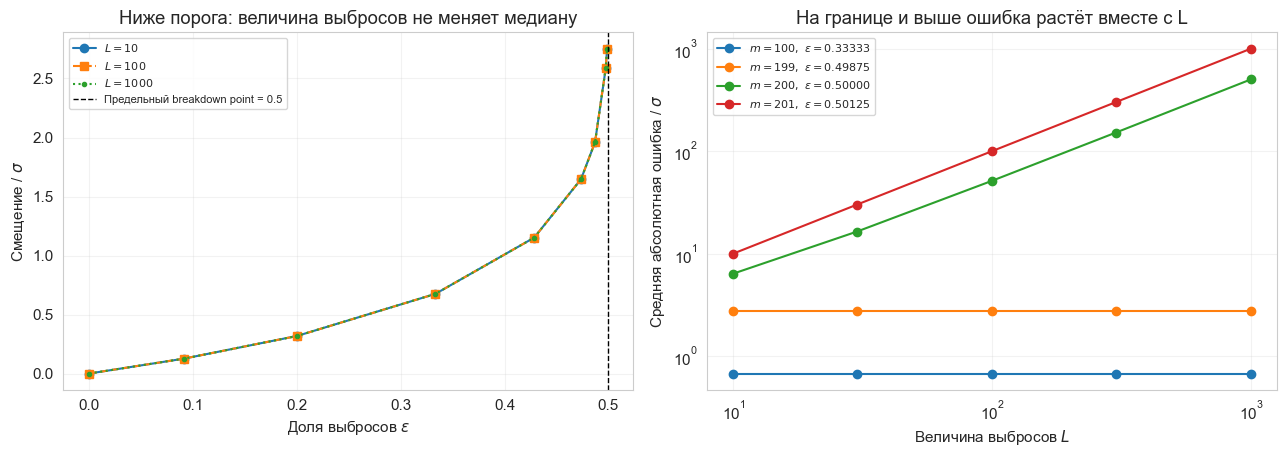

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
styles_bp = {10.0: ("-", "o"), 100.0: ("--", "s"), 1000.0: (":", ".")}
for L, (line_style, marker) in styles_bp.items():
    part = results_bp[(results_bp["L"] == L) & (results_bp["m"] < N_CLEAN_BP)]
    axes[0].plot(part['epsilon'], part['Смещение / sigma'],
                 linestyle=line_style, marker=marker, label=rf"$L = {L:g}$")
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1,
                label="Предельный breakdown point = 0.5")
axes[0].set(xlabel='Доля выбросов $\\epsilon$', ylabel='Смещение / $\\sigma$',
            title="Ниже порога: величина выбросов не меняет медиану")
axes[0].legend(fontsize=8)

for m in (100, 199, 200, 201):
    part = results_bp[results_bp["m"] == m]
    epsilon = m / (N_CLEAN_BP + m)
    axes[1].plot(part["L"], part['Средняя абсолютная ошибка / sigma'],
                 marker="o", label=rf"$m = {m},\ \epsilon = {epsilon:.5f}$")
axes[1].set(xscale="log", yscale="log", xlabel='Величина выбросов $L$',
            ylabel='Средняя абсолютная ошибка / $\\sigma$',
            title="На границе и выше ошибка растёт вместе с L")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

На первом графике кривые для разных $L$ совпали: пока обычные наблюдения составляют большинство, увеличение величины правых выбросов не меняет медиану. Смещение при этом возрастает с долей выбросов. На втором графике ниже порога ошибка постоянна по $L$, а на границе и выше растёт вместе с ним.

### 4. Проверим роль расположения выбросов

Breakdown point описывает долю выбросов, начиная с которой можно неограниченно изменить оценку при определённом выборе их значений. Это не означает, что при превышении порога оценка разрушается при любом расположении выбросов.

При $m=300$ доля выбросов равна $0.6$. Сравним все выбросы справа и по 150 выбросов с каждой стороны в точках $\mu\pm L\,\sigma$. Во втором случае, если эти точки лежат вне диапазона обычных данных, центральными остаются те же два обычных наблюдения, поэтому медиана совпадает с исходной.

In [37]:
clean_medians_bp = np.median(clean_bp, axis=1)
placement_records_bp = []
for L in (10.0, 100.0, 1000.0):
    left_outlier = MU_BP - L * SIGMA_BP
    right_outlier = MU_BP + L * SIGMA_BP
    assert left_outlier < clean_bp.min() and right_outlier > clean_bp.max()
    balanced = np.concatenate([np.full((REPEATS_BP, 150), left_outlier),
                               clean_bp,
                               np.full((REPEATS_BP, 150), right_outlier)], axis=1)
    balanced_medians = np.median(balanced, axis=1)
    np.testing.assert_allclose(balanced_medians, clean_medians_bp, rtol=0, atol=1e-12)
    for placement, medians in [("Все справа", estimates_bp[(L, 300)]),
                               ("Поровну с двух сторон", balanced_medians)]:
        errors = (medians - MU_BP) / SIGMA_BP
        placement_records_bp.append({"L": L, "Расположение выбросов": placement,
                                     'epsilon': 0.6,
                                     'Смещение / sigma': errors.mean(),
                                     'MSE/sigma^2': np.mean(errors**2)})
placement_bp = pd.DataFrame(placement_records_bp)
display(placement_bp)

,L,Расположение выбросов,epsilon,Смещение / sigma,MSE/sigma^2
0,10.0,Все справа,0.6,10.0000,100.00000
1,10.0,Поровну с двух сторон,0.6,0.0018,0.00795
2,100.0,Все справа,0.6,100.0000,10000.00000
3,100.0,Поровну с двух сторон,0.6,0.0018,0.00795
4,1000.0,Все справа,0.6,1000.0000,1000000.00000
5,1000.0,Поровну с двух сторон,0.6,0.0018,0.00795


При доле 0.6 и всех выбросах справа смещение растёт от $10\,\sigma$ до $1000\,\sigma$. Если выбросы распределены поровну с двух сторон, медиана точно совпадает с исходной при всех исследованных $L$; MSE остаётся около $0.00795\,\sigma^2$. Значит, превышение breakdown point означает потерю гарантии ограниченности при произвольных значениях выбросов, а не разрушение при любом расположении выбросов.

### Вывод

Мы эмпирически исследовали медиану с предельным breakdown point $1/2$. При добавлении менее 200 выбросов к 200 обычным наблюдениям оценка остаётся ограниченной независимо от величины выбросов. При 200 выбросах она растёт как половина их величины, а при большем числе совпадает с односторонними выбросами.

Информативность в смысле breakdown point означает сохранение ограниченности, а не отсутствие смещения или малую MSE. Уже ниже порога ошибка может быть существенной. Кроме доли выбросов важно их расположение: даже выше порога добавление симметрично расположенных выбросов может сохранить медиану, хотя гарантии устойчивости к произвольным выбросам уже нет.

## Задание 3. Эффективность, максимальное смещение и распределение Коши

Мы сравним M-оценки Губера и bisquare с предварительной оценкой масштаба по MAD. Выберем эффективность $\Delta=0.95$ для нормального распределения, исследуем смещение при выбросах в одной точке и проверим асимптотические дисперсии для распределения Коши.

### 1. Оценим масштаб и зададим M-оценки

Мы рассмотрим выборку $X_i=\mu+\sigma Z_i$, $Z_i\sim N(0,1)$, с $\mu=5$, $\sigma=2$. Сначала вычислим
$$\operatorname{MAD}=\operatorname{Med}|X_i-\operatorname{Med}(X)|,\qquad
\hat\sigma=\frac{\operatorname{MAD}}{q_N},\quad q_N=\Phi^{-1}(0.75).$$
Нормировка обеспечивает $\hat\sigma\xrightarrow{P}\sigma$; оценка дисперсии равна $\hat\sigma^2$. После этого зафиксируем $\hat\sigma$ и решим
$$\sum_i\psi_c\!\left(\frac{X_i-\hat\mu}{\hat\sigma}\right)=0.$$
Используем функции
$$\psi_{H,c}(u)=\max(-c,\min(u,c)),\qquad
\psi_{B,c}(u)=u\left(1-\frac{u^2}{c^2}\right)^2\mathbf1_{\{|u|<c\}}.$$
Найдём оценки методом итераций с весами $w(u)=\psi(u)/u$, $w(0)=1$, начиная с медианы. Для bisquare это задаёт выбор решения около центра распределения; произвольные корни уравнения не рассматриваем.

In [38]:
MU_3, SIGMA_3, DELTA_3 = 5.0, 2.0, 0.95
Q_NORMAL_3 = norm.ppf(0.75)
Q_CAUCHY_3 = cauchy.ppf(0.75)
KINDS_3 = ("huber", "bisquare")
LABELS_3 = {"huber": "Губер", "bisquare": "Bisquare"}
rng_demo_3 = np.random.default_rng(27102030)
rng_bias_3 = np.random.default_rng(27102031)
rng_cauchy_3 = np.random.default_rng(27102032)
pd.set_option("display.precision", 5)
pd.set_option("display.html.use_mathjax", True)

def psi_3(u, c, kind):
    u = np.asarray(u)
    if kind == "huber":
        return np.clip(u, -c, c)
    v = np.maximum(0.0, 1.0 - (u / c)**2)
    return u * v**2

def dpsi_3(u, c, kind):
    u = np.asarray(u)
    if kind == "huber":
        return (np.abs(u) < c).astype(float)
    z = (u / c)**2
    return np.where(np.abs(u) < c, (1 - z) * (1 - 5 * z), 0.0)

def mad_scale_3(samples, q):
    x = np.atleast_2d(np.asarray(samples, dtype=float))
    center = np.median(x, axis=1)
    scale = np.median(np.abs(x - center[:, None]), axis=1) / q
    if np.any(scale <= 0):
        raise ValueError("Для выбранной схемы требуется положительный MAD")
    return center, scale

def fit_location_3(samples, scale, c, kind, tol=1e-9, max_iter=300):
    x = np.atleast_2d(np.asarray(samples, dtype=float))
    scale = np.broadcast_to(np.asarray(scale), (len(x),))
    t = np.median(x, axis=1)
    for _ in range(max_iter):
        u = (x - t[:, None]) / scale[:, None]
        if kind == "huber":
            weights = np.minimum(1.0, c / np.maximum(np.abs(u), 1e-300))
        else:
            weights = np.maximum(0.0, 1.0 - (u / c)**2)**2
        new_t = np.sum(weights * x, axis=1) / weights.sum(axis=1)
        change = np.max(np.abs(new_t - t) / scale)
        t = new_t
        if change < tol:
            score = np.mean(psi_3((x - t[:, None]) / scale[:, None], c, kind), axis=1)
            if np.max(np.abs(score)) > 1e-8:
                raise RuntimeError("Уравнение M-оценки не выполнено с заданной точностью")
            return t
    raise RuntimeError("Метод итераций не достиг заданной точности")

demo_normal_3 = rng_demo_3.normal(MU_3, SIGMA_3, size=1001)
_, demo_scale_3 = mad_scale_3(demo_normal_3, Q_NORMAL_3)
print(f"q_N = {Q_NORMAL_3:.6f}")
print(f"MAD = {demo_scale_3[0] * Q_NORMAL_3:.5f}")
print(f"Оценка sigma по нормированному MAD = {demo_scale_3[0]:.5f}")

q_N = 0.674490
MAD = 1.35860
Оценка sigma по нормированному MAD = 2.01426


На выбранной выборке MAD равен 1.35860, а нормированная оценка масштаба - 2.01426, что близко к $\sigma=2$. Нормировка существенна: для нормального распределения сам MAD стремится к $q_N\sigma$, а не к $\sigma$.

### 2. Подберём параметры для эффективности 0.95

Положим $A_c=\mathbb E\psi'_c(Z)$, $B_c=\mathbb E\psi_c(Z)^2$. Производные равны
$$\psi'_{H,c}(u)=\mathbf1_{\{|u|<c\}},\qquad
\psi'_{B,c}(u)=\left(1-\frac{u^2}{c^2}\right)
\left(1-5\frac{u^2}{c^2}\right)\mathbf1_{\{|u|<c\}}.$$
Для симметричного распределения $\mathbb E[Z\psi'_c(Z)]=0$. Поэтому ошибка предварительной оценки масштаба не входит в первый член разложения оценки сдвига, и
$$v_c^2=\sigma^2\frac{B_c}{A_c^2},\qquad
\operatorname{Eff}_N(c)=\frac{\sigma^2}{v_c^2}=\frac{A_c^2}{B_c}.$$
Численно решим $\operatorname{Eff}_N(c)=0.95$ для каждой функции. Ожидания пока берём по $N(0,1)$.

In [39]:
def moments_3(c, kind, distribution):
    pdf = distribution.pdf
    if kind == "huber":
        a = 2 * distribution.cdf(c) - 1
        b = 2 * quad(lambda z: z**2 * pdf(z), 0, c, epsabs=1e-11)[0]
        b += 2 * c**2 * distribution.sf(c)
    else:
        a = 2 * quad(lambda z: float(dpsi_3(z, c, kind)) * pdf(z),
                     0, c, epsabs=1e-11)[0]
        b = 2 * quad(lambda z: float(psi_3(z, c, kind))**2 * pdf(z),
                     0, c, epsabs=1e-11)[0]
    return a, b

def normal_efficiency_3(c, kind):
    a, b = moments_3(c, kind, norm)
    return a**2 / b

C_3 = {kind: brentq(lambda c: normal_efficiency_3(c, kind) - DELTA_3,
                    0.2, 10.0, xtol=1e-11) for kind in KINDS_3}
normal_moments_3 = {kind: moments_3(C_3[kind], kind, norm) for kind in KINDS_3}
calibration_records_3 = []
for kind in KINDS_3:
    a, b = normal_moments_3[kind]
    fitted = fit_location_3(demo_normal_3, demo_scale_3, C_3[kind], kind)[0]
    calibration_records_3.append({"Оценка": LABELS_3[kind], 'c': C_3[kind],
                                  'A_c': a, 'B_c': b,
                                  "Эффективность": a**2 / b,
                                  'v^2': SIGMA_3**2 * b / a**2,
                                  'Оценка mu': fitted})
calibration_3 = pd.DataFrame(calibration_records_3)
display(calibration_3)
np.testing.assert_allclose(calibration_3["Эффективность"], DELTA_3, rtol=0, atol=1e-9)

,Оценка,c,A_c,B_c,Эффективность,v^2,Оценка mu
0,Губер,1.34500,0.82137,0.71016,0.95,4.21053,4.91076
1,Bisquare,4.68506,0.75778,0.60446,0.95,4.21053,4.91486


Мы получили $c_H\approx1.34500$ и $c_B\approx4.68506$. Обе эффективности равны 0.95, а асимптотические дисперсии при $\sigma=2$ совпадают: $v^2\approx4.21053$. На демонстрационной выборке оценки сдвига равны примерно 4.91076 и 4.91486; их отличие от $\mu=5$ отражает случайную ошибку одной выборки.

### 3. Оценим максимальное смещение при малой доле выбросов

Определим $B(T,F_{\epsilon,G})=T((1-\epsilon)F+\epsilon G)-\mu$ и
$$\operatorname{MB}(\epsilon)=\sup_G|B(T,F_{\epsilon,G})|.$$
Для выбранного симметричного распределения функция влияния оценки с подстановкой MAD равна
$$\operatorname{IF}_c(x,F)=\frac{\sigma}{A_c}\psi_c\!\left(\frac{x-\mu}{\sigma}\right).$$
Поэтому
$$\gamma^*_H=\frac{\sigma c_H}{A_{c_H}},\qquad
\gamma^*_B=\frac{\sigma}{A_{c_B}}\frac{16c_B}{25\sqrt5}.$$
Для bisquare максимум $|\psi_c|$ достигается при $|u|=c/\sqrt5$.

При малом $\epsilon$ используем $\operatorname{MB}(\epsilon)=\epsilon\gamma^*+o(\epsilon)$.

In [40]:
gamma_3 = {}
local_bias_records_3 = []
for kind in KINDS_3:
    c = C_3[kind]
    a, _ = normal_moments_3[kind]
    maximum_psi = c if kind == "huber" else 16 * c / (25 * np.sqrt(5))
    gamma_3[kind] = SIGMA_3 * maximum_psi / a
    for epsilon in (0.01, 0.05, 0.10):
        local_bias_records_3.append({"Оценка": LABELS_3[kind], 'epsilon': epsilon,
                                     'gamma*': gamma_3[kind],
                                     'epsilon*gamma*': epsilon * gamma_3[kind]})
local_bias_3 = pd.DataFrame(local_bias_records_3)
display(local_bias_3)

,Оценка,epsilon,gamma*,epsilon*gamma*
0,Губер,0.01,3.27499,0.03275
1,Губер,0.05,3.27499,0.16375
2,Губер,0.10,3.27499,0.32750
3,Bisquare,0.01,3.53913,0.03539
4,Bisquare,0.05,3.53913,0.17696
5,Bisquare,0.10,3.53913,0.35391


Чувствительность к грубым ошибкам равна $\gamma_H^*\approx3.27499$ и $\gamma_B^*\approx3.53913$. При $\epsilon=0.10$ получаем локальные приближения максимального смещения 0.32750 и 0.35391. Несмотря на одинаковую эффективность для нормального распределения, наибольшее локальное влияние наблюдения у bisquare немного выше.

### 4. Найдём смещение при выбросах в одной точке

Рассмотрим $F_{\epsilon,a}=(1-\epsilon)N(0,1)+\epsilon\Delta_a$, где $a=(x_0-\mu)/\sigma$. На данных с выбросами MAD также меняется, поэтому пересчитаем его предельное значение.

Медиана распределения с выбросами равна
$$m_{\epsilon,a}=\min\!\left(\max\!\left(a,\Phi^{-1}\!\frac{1/2-\epsilon}{1-\epsilon}\right),
\Phi^{-1}\!\frac{1/2}{1-\epsilon}\right).$$
Для абсолютного отклонения функция распределения имеет вид
$$H(r)=(1-\epsilon)[\Phi(m_{\epsilon,a}+r)-\Phi(m_{\epsilon,a}-r)]
+\epsilon\mathbf1_{\{|a-m_{\epsilon,a}|\le r\}}.$$
Найдём её медиану $d_{\epsilon,a}$ и положим $s_{\epsilon,a}=d_{\epsilon,a}/q_N$. Это предельное отношение $\hat\sigma/\sigma$.

Вычислим асимптотическое смещение $B_{\epsilon,a}=\sigma t_{\epsilon,a}$ из уравнения
$$ (1-\epsilon)\int\psi_c\!\left(\frac{z-t}{s_{\epsilon,a}}\right)\varphi(z)\,dz
+\epsilon\psi_c\!\left(\frac{a-t}{s_{\epsilon,a}}\right)=0.$$
Для bisquare выбираем решение около нуля, соответствующее началу итераций с медианы. Сравним приближение $\epsilon\gamma^*$ с максимумом $|B_{\epsilon,a}|$ по значениям выбросов. Этот численный максимум относится к случаям, когда все выбросы совпадают; он не подменяет максимум по всем распределениям $G$ при конечном $\epsilon$.

In [41]:
nodes_3, weights_3 = leggauss(96)

def mixture_mad_3(a, epsilon):
    lower_median = norm.ppf((0.5 - epsilon) / (1 - epsilon))
    upper_median = norm.ppf(0.5 / (1 - epsilon))
    median = np.clip(a, lower_median, upper_median)
    def usual_distance_cdf(r):
        return norm.cdf(median + r) - norm.cdf(median - r)
    lower_d = brentq(lambda r: usual_distance_cdf(r) - (0.5 - epsilon) / (1 - epsilon),
                     0, 10, xtol=1e-12)
    upper_d = brentq(lambda r: usual_distance_cdf(r) - 0.5 / (1 - epsilon),
                     0, 10, xtol=1e-12)
    d = np.clip(abs(a - median), lower_d, upper_d)
    return median, d / Q_NORMAL_3

def normal_score_3(t, s, c, kind):
    if kind == "huber":
        left, right = t - c * s, t + c * s
        middle = norm.cdf(right) - norm.cdf(left)
        return ((norm.pdf(left) - norm.pdf(right) - t * middle) / s
                + c * (norm.sf(right) - norm.cdf(left)))
    u = c * nodes_3
    return c * s * np.sum(weights_3 * psi_3(u, c, kind) * norm.pdf(t + s * u))

def population_bias_3(a, epsilon, kind):
    _, s = mixture_mad_3(a, epsilon)
    c = C_3[kind]
    def score(t):
        return ((1 - epsilon) * normal_score_3(t, s, c, kind)
                + epsilon * float(psi_3((a - t) / s, c, kind)))
    # При выбранных малых epsilon этот интервал содержит центральное решение
    return brentq(score, -2.0, 2.0, xtol=1e-12)

point_max_records_3 = []
positive_grid_3 = np.linspace(0, 12, 121)
for epsilon in (0.01, 0.05, 0.10):
    for kind in KINDS_3:
        if kind == "huber":
            a_star = 12.0  # Здесь и MAD, и вклад правого выброса уже постоянны
        else:
            values = np.array([abs(population_bias_3(a, epsilon, kind))
                               for a in positive_grid_3])
            j = int(values.argmax())
            refined = minimize_scalar(lambda a: -abs(population_bias_3(a, epsilon, kind)),
                                      bounds=(positive_grid_3[max(0, j - 1)],
                                              positive_grid_3[min(len(values) - 1, j + 1)]),
                                      method="bounded", options={"xatol": 1e-8})
            a_star = refined.x
        point_max = SIGMA_3 * abs(population_bias_3(a_star, epsilon, kind))
        point_max_records_3.append({"Оценка": LABELS_3[kind], 'epsilon': epsilon,
                                    'epsilon*gamma*': epsilon * gamma_3[kind],
                                    "Максимум по точкам": point_max,
                                    'a при максимуме': a_star})
point_max_3 = pd.DataFrame(point_max_records_3)
display(point_max_3)

EPSILON_3 = 0.10
A_GRID_3 = np.linspace(-12, 12, 241)
curves_3 = {kind: np.array([population_bias_3(a, EPSILON_3, kind) for a in A_GRID_3])
            for kind in KINDS_3}
for kind in KINDS_3:
    np.testing.assert_allclose(curves_3[kind], -curves_3[kind][::-1], atol=1e-10, rtol=0)
print("Кривые смещения нечётные с точностью 1e-10")

,Оценка,epsilon,epsilon*gamma*,Максимум по точкам,a при максимуме
0,Губер,0.01,0.03275,0.03327,12.00000
1,Bisquare,0.01,0.03539,0.03594,2.13812
2,Губер,0.05,0.16375,0.17789,12.00000
3,Bisquare,0.05,0.17696,0.19205,2.32659
4,Губер,0.10,0.32750,0.39151,12.00000
5,Bisquare,0.10,0.35391,0.42274,2.61010


Кривые смещения нечётные с точностью 1e-10


При $\epsilon=0.01$ численные максимумы по точкам близки к $\epsilon\gamma^*$. При $\epsilon=0.10$ они равны примерно 0.39151 для Губера и 0.42274 для bisquare, то есть превышают локальные приближения. Здесь уже заметно изменение масштаба, оценённого по MAD.

Для Губера $a=12$ лежит на участке постоянного смещения. У bisquare максимум достигается около $a=2.61$, а не при наиболее удалённых выбросах.

### 5. Проверим смещение моделированием

Зафиксируем $\epsilon=0.10$. Для нескольких точек $a$ сгенерируем по 500 выборок объёма 2001 с выбросами: с вероятностью $\epsilon$ наблюдение равно $x_0=\mu+\sigma a$, иначе оно нормально. В каждой выборке заново оценим масштаб через MAD и вычислим обе M-оценки.

Среднее $(\hat\mu-\mu)/\sigma$ сравним с $t_{\epsilon,a}$. Стандартная ошибка среднего равна выборочному стандартному отклонению этих ошибок, делённому на $\sqrt R$. Она описывает погрешность усреднения; конечный объём выборки также может влиять на результат.

In [42]:
R_BIAS_3, N_BIAS_3 = 500, 2001
EMPIRICAL_A_3 = (-8.0, -3.0, 0.0, 2.0, 3.0, 8.0)
bias_records_3 = []
for a in EMPIRICAL_A_3:
    samples = rng_bias_3.normal(MU_3, SIGMA_3, size=(R_BIAS_3, N_BIAS_3))
    contaminated = rng_bias_3.random(samples.shape) < EPSILON_3
    samples[contaminated] = MU_3 + SIGMA_3 * a
    _, scale = mad_scale_3(samples, Q_NORMAL_3)
    for kind in KINDS_3:
        fitted = fit_location_3(samples, scale, C_3[kind], kind)
        errors = (fitted - MU_3) / SIGMA_3
        bias_records_3.append({"Оценка": LABELS_3[kind], 'a': a,
                               'Теоретическое B/sigma': population_bias_3(a, EPSILON_3, kind),
                               'Среднее (mu_hat-mu)/sigma': errors.mean(),
                               "SE среднего": errors.std(ddof=1) / np.sqrt(R_BIAS_3),
                               'Среднее sigma_hat/sigma': scale.mean() / SIGMA_3})
bias_mc_3 = pd.DataFrame(bias_records_3)
display(bias_mc_3)

,Оценка,a,Теоретическое B/sigma,Среднее (mu_hat-mu)/sigma,SE среднего,Среднее sigma_hat/sigma
0,Губер,-8.0,-0.19576,-0.19842,0.00127,1.14441
1,Bisquare,-8.0,0.00000,-0.00203,0.00106,1.14441
2,Губер,-3.0,-0.19576,-0.19488,0.00131,1.14347
3,Bisquare,-3.0,-0.20414,-0.20286,0.00143,1.14347
4,Губер,0.0,0.00000,-0.00012,0.00096,0.87499
5,Bisquare,0.0,0.00000,-0.00008,0.00096,0.87499
6,Губер,2.0,0.19576,0.19813,0.00130,1.14445
7,Bisquare,2.0,0.19531,0.19727,0.00119,1.14445
8,Губер,3.0,0.19576,0.19666,0.00130,1.14738
9,Bisquare,3.0,0.20414,0.20514,0.00141,1.14738


Средние ошибки отличаются от рассчитанного $B/\sigma$ не более чем примерно на 0.0027. Расхождения невелики относительно погрешности усреднения и конечного объёма выборок. Подстановка MAD действительно меняется со значением выбросов: среднее $\hat\sigma/\sigma$ составляет около 0.875 при $a=0$ и около 1.14 при удалённых выбросах.

Построим асимптотическое смещение в зависимости от значения выбросов $a=(x_0-\mu)/\sigma$. Сплошная линия соответствует решению уравнения для распределения с выбросами, штриховая - приближению $\epsilon\operatorname{IF}(x_0,F)/\sigma$. Точки покажут результаты моделирования с интервалами в 1.96 стандартной ошибки среднего.

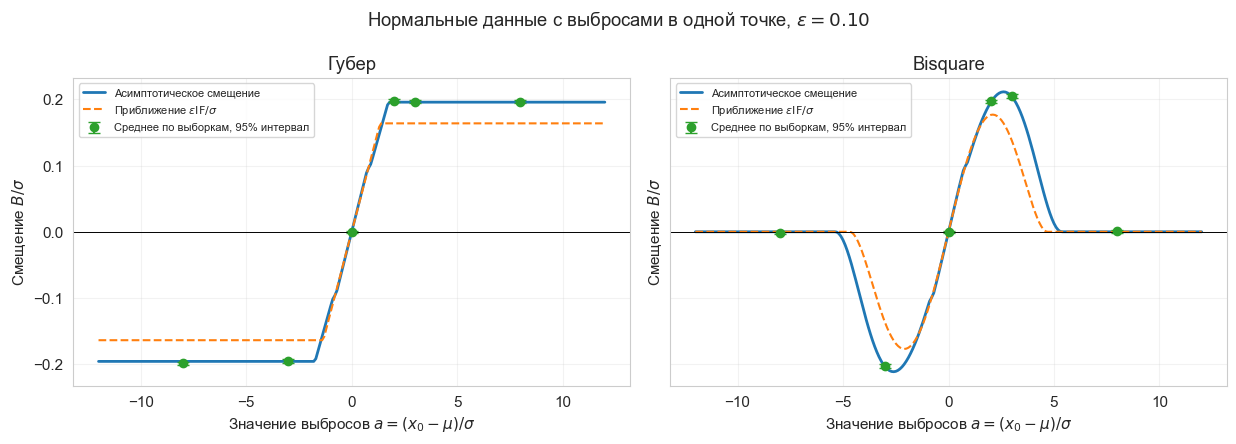

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), sharey=True)
for ax, kind in zip(axes, KINDS_3):
    a_normal, _ = normal_moments_3[kind]
    first_order = EPSILON_3 * psi_3(A_GRID_3, C_3[kind], kind) / a_normal
    part = bias_mc_3[bias_mc_3["Оценка"] == LABELS_3[kind]]
    ax.plot(A_GRID_3, curves_3[kind], linewidth=2, label="Асимптотическое смещение")
    ax.plot(A_GRID_3, first_order, "--", label=r"Приближение $\epsilon\mathrm{IF}/\sigma$")
    ax.errorbar(part['a'], part['Среднее (mu_hat-mu)/sigma'],
                yerr=1.96 * part["SE среднего"], fmt="o", capsize=4,
                label="Среднее по выборкам, 95% интервал")
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set(xlabel=r"Значение выбросов $a=(x_0-\mu)/\sigma$",
           ylabel=r"Смещение $B/\sigma$", title=LABELS_3[kind])
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle(r"Нормальные данные с выбросами в одной точке, $\epsilon=0.10$")
plt.tight_layout()
plt.show()

У Губера смещение при увеличении расстояния от выбросов до центра распределения выходит на ненулевой постоянный уровень. У bisquare после максимума оно возвращается к нулю: достаточно удалённый точечный выброс получает нулевой вес в выбранном центральном решении. При $\epsilon=0.10$ приближение через IF передаёт общий вид кривых, но не даёт точного смещения.

### 6. Перейдём к распределению Коши

Теперь $X_i=\mu+\sigma Z_i$, где $Z_i\sim\operatorname{Cauchy}(0,1)$ с плотностью $f(z)=1/[\pi(1+z^2)]$. Здесь $\mu$ - параметр сдвига, а $\sigma$ - масштаб: математическое ожидание и дисперсия распределения Коши не существуют.

Поскольку $\operatorname{Med}|Z|=1$, состоятельная оценка масштаба теперь равна ненормированному MAD. Сохраним найденные $c_H,c_B$, но возьмём $q_C=1$ вместо $q_N$. Нормировка для нормального закона дала бы другую предельную величину масштаба и потребовала бы изменения расчётов.

Из симметрии снова следует $\mathbb E[Z\psi'_c(Z)]=0$, поэтому
$$v_{C,c}^2=\sigma^2\frac{\mathbb E_C\psi_c(Z)^2}{[\mathbb E_C\psi'_c(Z)]^2}.$$
Ограниченность $\psi$ обеспечивает существование числителя. Для Губера дополнительно получим
$$A_{C,c}=\frac{2\arctan c}{\pi},\qquad
B_{C,c}=\frac{2(c-\arctan c)}{\pi}+c^2(1-A_{C,c}).$$
Для bisquare вычислим оба интеграла по $[-c_B,c_B]$.

In [44]:
cauchy_moments_3 = {kind: moments_3(C_3[kind], kind, cauchy) for kind in KINDS_3}
v2_cauchy_3 = {}
cauchy_theory_records_3 = []
for kind in KINDS_3:
    a, b = cauchy_moments_3[kind]
    v2_cauchy_3[kind] = SIGMA_3**2 * b / a**2
    cauchy_theory_records_3.append({"Оценка": LABELS_3[kind], 'c': C_3[kind],
                                   'A_C(c)': a, 'B_C(c)': b,
                                   'v_C^2': v2_cauchy_3[kind]})
cauchy_theory_3 = pd.DataFrame(cauchy_theory_records_3)
display(cauchy_theory_3)
c = C_3["huber"]
a_exact = 2 * np.arctan(c) / np.pi
b_exact = 2 * (c - np.arctan(c)) / np.pi + c**2 * (1 - a_exact)
np.testing.assert_allclose(cauchy_moments_3["huber"], [a_exact, b_exact], atol=1e-10, rtol=0)
print(f"Калибровка MAD для распределения Коши: q_C = {Q_CAUCHY_3:g}")

,Оценка,c,A_C(c),B_C(c),v_C^2
0,Губер,1.34500,0.59299,0.99954,11.37005
1,Bisquare,4.68506,0.49209,0.56913,9.40114


Калибровка MAD для распределения Коши: q_C = 1


При сохранённых параметрах функций получили $v_{C,H}^2\approx11.37005$ и $v_{C,B}^2\approx9.40114$. Для распределения Коши оценка bisquare имеет меньшую асимптотическую дисперсию. Равенство эффективностей для нормального распределения не сохраняется автоматически при смене распределения.

### 7. Проверим дисперсии M-оценок для распределения Коши

Для $n=201,1001,3001$ выполним по $R=4000$ независимых повторений. В каждой выборке подставим её MAD и вычислим обе оценки сдвига. Сравним
$$\widehat v_n^2=n\,\widehat{\operatorname{Var}}(\hat\mu)
\quad\text{с}\quad v_{C,c}^2.$$
Для $Y_r=\sqrt n(\hat\mu^{(r)}-\mu)$ оценим погрешность дисперсии через четвёртый центральный момент:
$$\widehat{\operatorname{SE}}(\widehat v_n^2)=
\sqrt{\frac{\max(0,\hat m_4-(\widehat v_n^2)^2)}R},\qquad
\hat m_4=\frac1R\sum_r(Y_r-\bar Y)^4.$$
Дисперсия самих наблюдений не вычисляется: исследуем дисперсии робастных оценок сдвига.

In [45]:
R_CAUCHY_3, BATCH_CAUCHY_3 = 4000, 200
SIZES_CAUCHY_3 = (201, 1001, 3001)
cauchy_sim_records_3 = []
for n in SIZES_CAUCHY_3:
    estimates = np.empty((R_CAUCHY_3, 2))
    scales = np.empty(R_CAUCHY_3)
    for start in range(0, R_CAUCHY_3, BATCH_CAUCHY_3):
        stop = min(start + BATCH_CAUCHY_3, R_CAUCHY_3)
        samples = MU_3 + SIGMA_3 * rng_cauchy_3.standard_cauchy(size=(stop - start, n))
        _, scale = mad_scale_3(samples, Q_CAUCHY_3)
        scales[start:stop] = scale
        for j, kind in enumerate(KINDS_3):
            estimates[start:stop, j] = fit_location_3(samples, scale, C_3[kind], kind)
    for j, kind in enumerate(KINDS_3):
        y = np.sqrt(n) * (estimates[:, j] - MU_3)
        empirical_v2 = y.var(ddof=1)
        m4 = np.mean((y - y.mean())**4)
        se = np.sqrt(max(0, m4 - empirical_v2**2) / R_CAUCHY_3)
        theoretical_v2 = v2_cauchy_3[kind]
        cauchy_sim_records_3.append({'n': n, "Оценка": LABELS_3[kind],
                                     'Смещение mu_hat': estimates[:, j].mean() - MU_3,
                                     'Среднее sigma_hat/sigma': scales.mean() / SIGMA_3,
                                     'n*Var(mu_hat)': empirical_v2,
                                     'v_C^2': theoretical_v2, "SE дисперсии": se,
                                     "Относительная ошибка, %": 100 * (empirical_v2 / theoretical_v2 - 1)})
    print(f"Распределение Коши: завершены {R_CAUCHY_3} повторений при n = {n}", flush=True)
cauchy_simulation_3 = pd.DataFrame(cauchy_sim_records_3)
display(cauchy_simulation_3)

Распределение Коши: завершены 4000 повторений при n = 201
Распределение Коши: завершены 4000 повторений при n = 1001
Распределение Коши: завершены 4000 повторений при n = 3001


,n,Оценка,Смещение mu_hat,Среднее sigma_hat/sigma,n*Var(mu_hat),v_C^2,SE дисперсии,"Относительная ошибка, %"
0,201,Губер,-0.00152,1.00409,10.87157,11.37005,0.26035,-4.38415
1,201,Bisquare,-0.00331,1.00409,9.35270,9.40114,0.22333,-0.51529
2,1001,Губер,-0.00235,0.99961,11.17586,11.37005,0.24783,-1.70796
3,1001,Bisquare,-0.00237,0.99961,9.32564,9.40114,0.21268,-0.80315
4,3001,Губер,0.00107,1.00011,11.77109,11.37005,0.26955,3.52717
5,3001,Bisquare,0.00066,1.00011,9.46117,9.40114,0.21522,0.63847


При $n=3001$ получили $n\widehat{\operatorname{Var}}(\hat\mu)\approx11.77109$ для Губера и 9.46117 для bisquare. Относительные отклонения от пределов составляют около 3.53% и 0.64%. Среднее $\hat\sigma/\sigma\approx1.00011$, что согласуется с состоятельностью MAD для масштаба Коши. Случайные колебания при конечном числе повторений не обязаны уменьшаться монотонно с $n$.

Построим масштабированные дисперсии оценок и их теоретические пределы. Отрезки в 1.96 стандартной ошибки покажут приближённую погрешность моделирования для каждого значения $n$ отдельно. Они не учитывают отличие дисперсии при конечном $n$ от её предела.

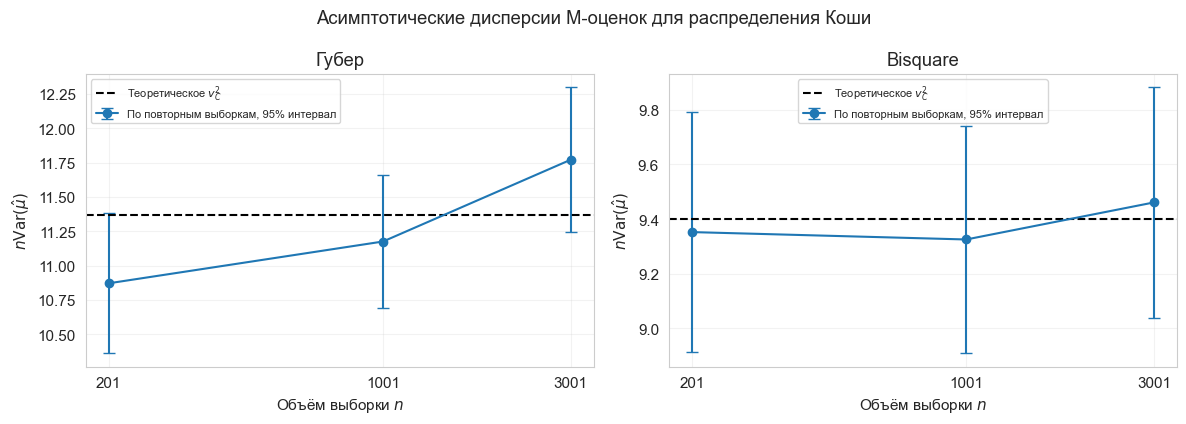

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, kind in zip(axes, KINDS_3):
    part = cauchy_simulation_3[cauchy_simulation_3["Оценка"] == LABELS_3[kind]]
    ax.errorbar(part['n'], part['n*Var(mu_hat)'],
                yerr=1.96 * part["SE дисперсии"], fmt="o-", capsize=4,
                label="По повторным выборкам, 95% интервал")
    ax.axhline(v2_cauchy_3[kind], color="black", linestyle="--", label=r"Теоретическое $v_C^2$")
    ax.set(xscale="log", xlabel=r"Объём выборки $n$", ylabel=r"$n\mathrm{Var}(\hat\mu)$",
           title=LABELS_3[kind])
    ax.set_xticks(SIZES_CAUCHY_3, [str(n) for n in SIZES_CAUCHY_3])
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("Асимптотические дисперсии M-оценок для распределения Коши")
plt.tight_layout()
plt.show()

Теоретическое значение попало в соответствующий приближённый интервал во всех шести ситуациях. Это согласуется с формулой асимптотической дисперсии в пределах точности моделирования. На всех исследованных объёмах выборки дисперсия bisquare меньше дисперсии оценки Губера.

### Вывод

Мы подобрали $c_H\approx1.345$ и $c_B\approx4.685$ для эффективности $\Delta=0.95$ при подстановке нормированного MAD. Максимальное смещение при малой доле выбросов оценивается произведением $\epsilon\gamma^*$; при фиксированной доле нужно учитывать изменение распределения и MAD.

У Губера меньше локальная чувствительность к грубым ошибкам, а bisquare исключает влияние достаточно удалённых точечных выбросов в выбранном решении. Для распределения Коши с калибровкой MAD для его масштаба bisquare даёт меньшую асимптотическую дисперсию: примерно 9.40114 против 11.37005. Моделирование согласуется с этими расчётами.